<a href="https://colab.research.google.com/github/komazawa-deep-learning/komazawa-deep-learning.github.io/blob/master/2026notebooks/2026_1127pe_2x2_shuffle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# エンコーダとデコーダ，どちらの PE が効いているのか: 2×2 設計と並べ替えテスト

`pe_three_conditions.ipynb` では PE をエンコーダとデコーダの両方に入れて比べた。
ここでは両者を **別々に** 入れたり外したりして，どちら側の PE が何をしているかを切り分ける。

|  | デコーダ PE なし | デコーダ PE あり |
|---|---|---|
| **エンコーダ PE なし** | none / none | none / PE |
| **エンコーダ PE あり** | PE / none | PE / PE |

さらに **並べ替えテスト** を行う。学習済みモデルに，上の句の文字順をでたらめに並べ替えた入力を与える。

* エンコーダに PE がなければ，出力は **まったく変わらない** はずである (理由は最後の節)。
* エンコーダに PE があれば，出力は崩れるはずである。

正解率の比較よりも，PE が「順序の情報を入れる装置」であることを直接示せる。

## 1. 準備

In [2]:
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules

REPO_URL = 'https://github.com/ShinAsakawa/CDP_ja.git'   # 2 ファイルを置いたリポジトリ
NEEDED = ['pe_transformer.py', 'chihaya.json']

def find_dir():
    for d in ['.', 'CDP_ja']:
        if all(os.path.exists(os.path.join(d, f)) for f in NEEDED):
            return d
    return None

WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    if not os.path.exists('CDP_ja'):
        subprocess.run(['git', 'clone', '-q', REPO_URL], check=False)
    WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    from google.colab import files
    print('pe_transformer.py と chihaya.json をアップロードしてください')
    files.upload()
    WORK_DIR = find_dir()
assert WORK_DIR is not None, f'{NEEDED} が見つからない。このノートブックと同じフォルダに置くこと'
sys.path.insert(0, os.path.abspath(WORK_DIR))
DATA_PATH = os.path.join(WORK_DIR, 'chihaya.json')

# 日本語フォント
try:
    import japanize_matplotlib
except Exception:
    try:
        import matplotlib_fontja
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'matplotlib-fontja'], check=False)
        import matplotlib_fontja

%config InlineBackend.figure_format = 'retina'
import numpy as np
import torch
import matplotlib.pyplot as plt
import pe_transformer as pt

# デバイス: cuda (Colab GPU) > mps (Apple Silicon) > cpu
# このモデルは非常に小さいので，mps より cpu の方が速いことがある。その場合は下の行を有効にする
DEVICE = pt.get_device()
# DEVICE = torch.device('cpu')
print('Colab:', IN_COLAB, '| device:', DEVICE, '| torch:', torch.__version__, '| 作業フォルダ:', os.path.abspath(WORK_DIR))

Colab: True | device: cuda | torch: 2.14.1+cu130 | 作業フォルダ: /content/CDP_ja


In [3]:
pairs = pt.load_chihaya(DATA_PATH)   # [(上の句, 下の句), ...] ひらがな，濁点は除去して統一
vocab = pt.Vocab(pairs)
print('歌数:', len(pairs), '| 語彙数 (特殊トークン含む):', len(vocab))
print('上の句の最大長:', max(len(k) for k, _ in pairs), '| 下の句の最大長:', max(len(s) for _, s in pairs))
for k, s in pairs[:3]:
    print(f'  {k}  →  {s}')

歌数: 100 | 語彙数 (特殊トークン含む): 51
上の句の最大長: 19 | 下の句の最大長: 16
  あきのたのかりほのいほのとまをあらみ  →  わかころもてはつゆにぬれつつ
  はるすきてなつきにけらししろたへの  →  ころもほすてふあまのかくやま
  あしひきのやまとりのをのしたりをの  →  なかなかしよをひとりかもねむ


## 2. 予備調査: 上の句は「文字の集まり」だけで区別できるか

PE のないエンコーダは文字の順序を区別できない。上の句を **文字の多重集合** (順序を捨てて，どの文字が何回出たかだけを見る) にしたときに，100 首がすべて区別できるなら，
エンコーダに PE がなくても課題は解ける可能性がある。

In [4]:
from collections import Counter
bags = [tuple(sorted(Counter(k).items())) for k, _ in pairs]
print('異なる多重集合の数:', len(set(bags)), '/', len(pairs))
dups = [k for k, c in Counter(bags).items() if c > 1]
print('区別できない組:', dups if dups else 'なし → 文字の集まりだけで 100 首すべてを特定できる')

異なる多重集合の数: 100 / 100
区別できない組: なし → 文字の集まりだけで 100 首すべてを特定できる


## 3. 2×2 条件の学習

`PE_TYPE` を `'rope'` に変えれば，RoPE で同じ実験ができる。

In [5]:
PE_TYPE = 'sinusoidal'   # 'sinusoidal' または 'rope'
cfg = pt.Config(model_dim=32, num_heads=4, num_layers=1, ff_dim=32,
                epochs=300, batch_size=10, lr=1e-3, lr_schedule='cosine', eval_every=300)
SEEDS = [0, 1, 2]
CONDS = [('none', 'none'), ('none', PE_TYPE), (PE_TYPE, 'none'), (PE_TYPE, PE_TYPE)]

models, orig_acc = {}, {}
for enc_pe, dec_pe in CONDS:
    for seed in SEEDS:
        cfg.seed = seed
        model, h = pt.train(cfg, pairs, vocab, enc_pe=enc_pe, dec_pe=dec_pe, device=DEVICE, verbose=False)
        models[(enc_pe, dec_pe, seed)] = model
        orig_acc[(enc_pe, dec_pe, seed)] = h['exact'][-1]
    accs = [orig_acc[(enc_pe, dec_pe, s)] for s in SEEDS]
    print(f'エンコーダ {enc_pe:>10s} / デコーダ {dec_pe:<10s}: 完全一致 {np.mean(accs):.3f}  (各シード {accs})')

エンコーダ       none / デコーダ none      : 完全一致 0.990  (各シード [0.98, 0.99, 1.0])
エンコーダ       none / デコーダ sinusoidal: 完全一致 1.000  (各シード [1.0, 1.0, 1.0])
エンコーダ sinusoidal / デコーダ none      : 完全一致 0.997  (各シード [1.0, 0.99, 1.0])
エンコーダ sinusoidal / デコーダ sinusoidal: 完全一致 1.000  (各シード [1.0, 1.0, 1.0])


## 4. 並べ替えテスト

各モデルについて，上の句の文字順を 10 通りに並べ替えて入力する
(`<SOS>` と `<EOS>` の位置は固定)。次の 2 つを測る。

* **出力の最大変化量**: 元の入力と並べ替えた入力で，デコーダ出力 (ロジット) が最大どれだけ変わったか。
  0 に近ければ「並べ替えに対して不変」。
* **並べ替え後の完全一致率**: 並べ替えた上の句から，正しい下の句を生成できた割合。

In [6]:
N_SHUFFLE = 10
src_all, tin_all, _ = pt.make_tensors(pairs, vocab, DEVICE)

shuf_acc, max_diff = {}, {}
for (enc_pe, dec_pe, seed), model in models.items():
    model.eval()
    g = torch.Generator().manual_seed(1234)
    with torch.no_grad():
        base = model(src_all, tin_all)
        diffs, accs = [], []
        for _ in range(N_SHUFFLE):
            s2 = pt.shuffle_src(src_all, g)
            diffs.append(float((model(s2, tin_all) - base).abs().max()))
            accs.append(pt.evaluate(model, s2, pairs, vocab)['exact'])
    max_diff[(enc_pe, dec_pe, seed)] = max(diffs)
    shuf_acc[(enc_pe, dec_pe, seed)] = float(np.mean(accs))

print(f'{"エンコーダ":>10s} {"デコーダ":>10s} | {"元の正解率":>8s} | {"並べ替え後":>8s} | {"出力の最大変化量":>14s}')
print('-' * 70)
for enc_pe, dec_pe in CONDS:
    o = np.mean([orig_acc[(enc_pe, dec_pe, s)] for s in SEEDS])
    a = np.mean([shuf_acc[(enc_pe, dec_pe, s)] for s in SEEDS])
    d = max(max_diff[(enc_pe, dec_pe, s)] for s in SEEDS)
    print(f'{enc_pe:>10s} {dec_pe:>10s} | {o:10.3f} | {a:10.3f} | {d:14.2e}')

     エンコーダ       デコーダ |    元の正解率 |    並べ替え後 |       出力の最大変化量
----------------------------------------------------------------------
      none       none |      0.990 |      0.990 |       4.63e-05
      none sinusoidal |      1.000 |      1.000 |       4.39e-05
sinusoidal       none |      0.997 |      0.000 |       3.51e+01
sinusoidal sinusoidal |      1.000 |      0.000 |       3.90e+01


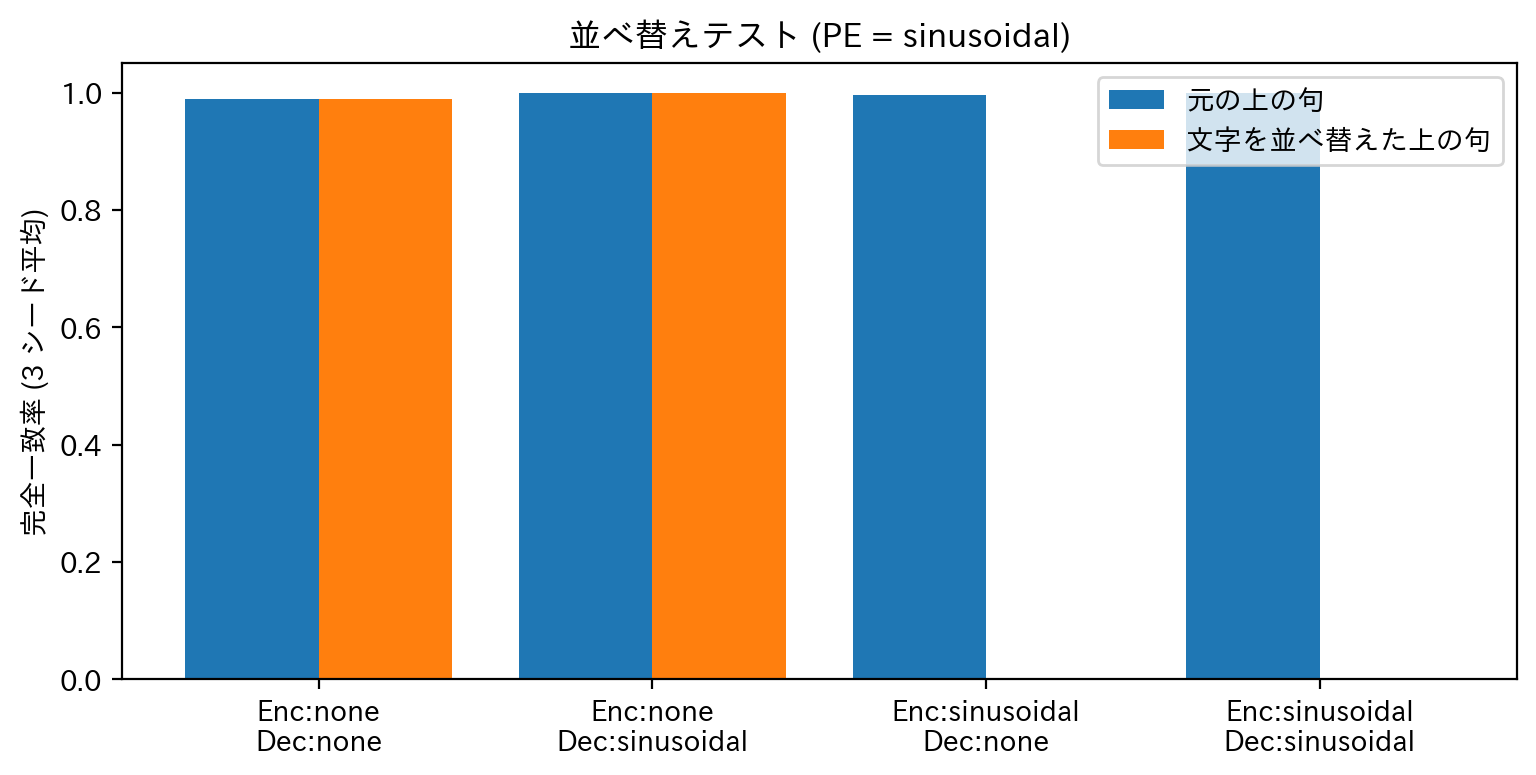

In [7]:
labels = [f'Enc:{e}\nDec:{d}' for e, d in CONDS]
o = [np.mean([orig_acc[(e, d, s)] for s in SEEDS]) for e, d in CONDS]
a = [np.mean([shuf_acc[(e, d, s)] for s in SEEDS]) for e, d in CONDS]
x = np.arange(len(CONDS))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, o, 0.4, label='元の上の句', color='tab:blue')
plt.bar(x + 0.2, a, 0.4, label='文字を並べ替えた上の句', color='tab:orange')
plt.xticks(x, labels); plt.ylim(0, 1.05); plt.ylabel('完全一致率 (3 シード平均)')
plt.title(f'並べ替えテスト (PE = {PE_TYPE})'); plt.legend(); plt.show()

## 5. 具体例: 並べ替えた上の句から何が生成されるか

In [8]:
IDX = 16   # 17 番「ちはやふる」(0 始まり)
g = torch.Generator().manual_seed(7)
src1, _, _ = pt.make_tensors([pairs[IDX]], vocab, DEVICE)
src1_shuf = pt.shuffle_src(src1, g)
print('元の上の句     :', pairs[IDX][0])
print('並べ替えた上の句:', vocab.decode(src1_shuf[0, 1:].cpu()))
print('正解の下の句   :', pairs[IDX][1])
print()
for enc_pe, dec_pe in CONDS:
    m = models[(enc_pe, dec_pe, 0)]
    out_o = vocab.decode(pt.greedy_decode(m, src1)[0].cpu())
    out_s = vocab.decode(pt.greedy_decode(m, src1_shuf)[0].cpu())
    print(f'Enc:{enc_pe:>10s} Dec:{dec_pe:>10s} | 元 → {out_o:<16s} | 並べ替え → {out_s}')

元の上の句     : ちはやふるかみよもきかすたつたかは
並べ替えた上の句: きかふすよもみはたかつはかたるやち
正解の下の句   : からくれなゐにみつくくるとは

Enc:      none Dec:      none | 元 → からくれなゐにみつくくるとは   | 並べ替え → からくれなゐにみつくくるとは
Enc:      none Dec:sinusoidal | 元 → からくれなゐにみつくくるとは   | 並べ替え → からくれなゐにみつくくるとは
Enc:sinusoidal Dec:      none | 元 → からくれなゐにみつくくるとは   | 並べ替え → なつつのたるかなくはな
Enc:sinusoidal Dec:sinusoidal | 元 → からくれなゐにみつくくるとは   | 並べ替え → にひとひるかものむ


## 6. なぜ「エンコーダ PE なし」だと並べ替えても出力が変わらないのか

self-attention は，入力の順序を入れ替えると出力も同じように入れ替わるだけの演算である (**置換同変性**)。

入力 $X$ (行がトークン) の行を置換行列 $P$ で並べ替えると

$$
\mathrm{softmax}\!\left(\frac{(PX W_Q)(PX W_K)^\top}{\sqrt{d}}\right) PX W_V
= P\,\mathrm{softmax}\!\left(\frac{X W_Q (X W_K)^\top}{\sqrt{d}}\right) P^\top P X W_V
= P \cdot \mathrm{Attn}(X)
$$

となる ($P^\top P = I$，softmax は行ごとの演算)。フィードフォワード層と層正規化は位置ごとの演算なので，やはり順序を入れ替えるだけである。
つまり PE のないエンコーダの出力は，**上の句の並べ替えに応じて行が並べ替わるだけ** である。

デコーダの cross-attention はエンコーダ出力 (キーと値) の **全行について重み付き和** をとる。和は足す順序によらないので，
行が並べ替わっても結果は同じになる。したがって **下の句の生成は上の句の文字順に一切依存しない**。
表の「出力の最大変化量」が 0 に近い値 ($10^{-5}$ 程度) になるのは，浮動小数点の丸め誤差だけが残るためである。

PE を加えると，同じ文字でも位置によって異なるベクトルになるので，この対称性が壊れる。**PE とは，この置換対称性を壊して順序の情報を持ち込む装置である。**

## 7. 考えてみよう

1. エンコーダに PE がないモデルは，上の句をどのような情報として使っていると言えるか。2 節の結果とあわせて考えよ。
2. エンコーダに PE があるモデルは，並べ替えた上の句に対してほとんど正解できない。これは「PE があるモデルの方が劣っている」ことを意味するか。
3. デコーダ側の PE を外すと何が変わったか。5 節の生成例で，同じ文字が続く箇所 (「くくる」) の文字数は正しいか。
   デコーダは PE がなくても因果マスクを持つ。因果マスクだけで位置がある程度わかるのはなぜか。それでも数え間違えるのはなぜか。
4. 上の句の多重集合が重なる歌の組があったとしたら，エンコーダ PE なしのモデルはその組をどう扱うはずか。
5. `PE_TYPE = 'rope'` に変えて同じ実験をせよ。結論は変わるか。